<a href="https://colab.research.google.com/github/huiyzhao/MSSP607/blob/main/Assignments/huiyzhao_assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import subprocess

owner = "huiyzhao"
repository = "MSSP607"

repo_url = f"https://github.com/huiyzhao/MSSP607.git"

if not os.path.exists (repository):
  subprocess.run(["git", "clone", repo_url], check=True)

os.chdir(repository)
print("Current folder:", os.getcwd())

Current folder: /content/MSSP607


In [2]:
import pandas as pd
subprocess.run(["git", "pull"], check=True)
file_path = "data/InternetSales.csv"
sales = pd.read_csv(file_path, encoding="latin1", low_memory=False)

print("Rows and Columns:", sales.shape)
print("\nColumn names:")
print(sales.columns.tolist())

sales.head()

Rows and Columns: (60398, 60)

Column names:
['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'Custom

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [3]:
sales.columns

Index(['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode',
       'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title',
       'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate',
       'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome',
       'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation',
       'SpanishEducation', 'FrenchEducation', 'EnglishOccupation',
       'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag',
       'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone',
       'DateFirstPurchase', 'CommuteDistance', 'ProductKey',
       'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey',
       'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey',
       'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber',
       'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct',
       'DiscountAmount', 'ProductStandardCost', 'TotalProductCost',
       'SalesAmo

In [4]:
core = ['SalesAmount','UnitPrice','OrderQuantity']
desc_stats = sales[core].describe()
print(desc_stats)

        SalesAmount     UnitPrice  OrderQuantity
count  60398.000000  60398.000000        60398.0
mean     486.086911    486.086911            1.0
std      928.489892    928.489892            0.0
min        2.290000      2.290000            1.0
25%        7.950000      7.950000            1.0
50%       29.990000     29.990000            1.0
75%      539.990000    539.990000            1.0
max     3578.270000   3578.270000            1.0


In [5]:
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
sales["Year"] = sales["OrderDate"].dt.year
sales_year_region = sales.pivot_table(
    index="Year",
    columns="EnglishCountryRegionName",
    values="SalesAmount",
    aggfunc="sum"
)

sales_year_region

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,2.090978e+04,3.578270e+03,3.399990e+03,NaN,6.990982e+02,1.483390e+04
2011,2.563732e+06,5.715718e+05,4.108453e+05,5.205002e+05,5.505912e+05,2.458285e+06
2012,2.128407e+06,3.076045e+05,6.480655e+05,6.086580e+05,7.127010e+05,1.437049e+06
2013,4.339443e+06,1.085633e+06,1.578512e+06,1.761876e+06,2.124007e+06,5.462079e+06
2014,8.507720e+03,9.457620e+03,3.195060e+03,3.277830e+03,3.713640e+03,1.754285e+04


In [6]:
sales.groupby(sales["OrderDate"].dt.year)["OrderDate"].agg(["min","max","count"])

,min,max,count
OrderDate,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


In [7]:
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
sales["Year"] = sales["OrderDate"].dt.year
sales_fullyear = sales[
    sales["Year"].isin([2011,2012,2013])
]
sales_fullyear_region = sales_fullyear.pivot_table(
    index="Year",
    columns="EnglishCountryRegionName",
    values="SalesAmount",
    aggfunc="sum"
)

sales_fullyear_region

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2011,2.563732e+06,5.715718e+05,4.108453e+05,5.205002e+05,5.505912e+05,2.458285e+06
2012,2.128407e+06,3.076045e+05,6.480655e+05,6.086580e+05,7.127010e+05,1.437049e+06
2013,4.339443e+06,1.085633e+06,1.578512e+06,1.761876e+06,2.124007e+06,5.462079e+06


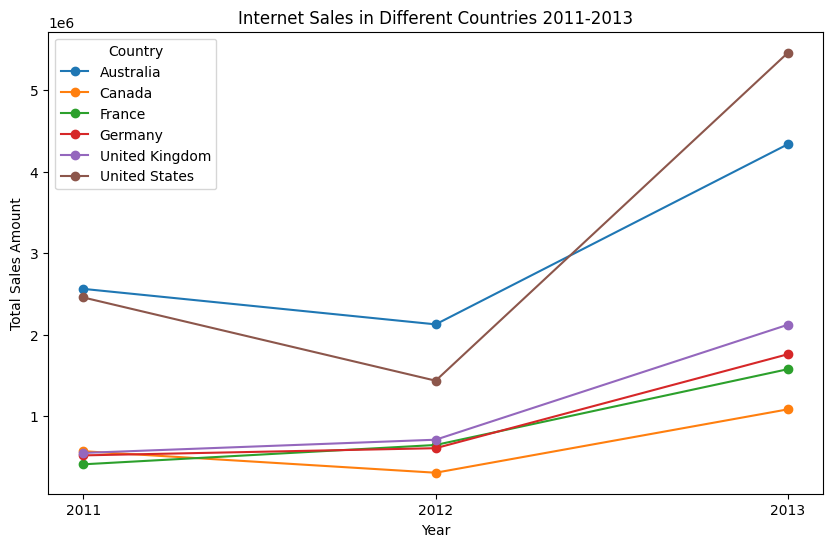

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

for country in sales_fullyear_region.columns:
  plt.plot(
      sales_fullyear_region.index,
      sales_fullyear_region[country],
      marker="o",
      label=country
  )

  plt.title("Internet Sales in Different Countries 2011-2013")
  plt.xlabel("Year")
  plt.ylabel("Total Sales Amount")
  plt.legend(title="Country")
  plt.xticks([2011,2012,2013])

In [9]:
income = sales.groupby(
    ["EnglishCountryRegionName", "Gender"]
)["YearlyIncome"].agg(["min","max","std"])

income

min     max           std
EnglishCountryRegionName Gender                             
Australia                F       10000  160000  30613.956169
                         M       10000  170000  32550.778171
Canada                   F       10000  170000  19435.158438
                         M       10000  170000  22702.851581
France                   F       10000  110000  28421.836245
                         M       10000  110000  28665.660622
Germany                  F       10000  130000  37622.814569
                         M       10000  130000  37487.619366
United Kingdom           F       10000  170000  51130.689140
                         M       10000  170000  50963.707551
United States            F       10000  170000  25498.805483
                         M       10000  170000  26520.348175

In [10]:
sales["EnglishProductName"].unique()

array(['Mountain-100 Silver, 38', 'Mountain-200 Silver, 38',
       'Fender Set - Mountain', 'Touring-1000 Blue, 46', 'Touring Tire',
       'Touring Tire Tube', 'Sport-100 Helmet, Red',
       'Short-Sleeve Classic Jersey, S', 'Water Bottle - 30 oz.',
       'Mountain Bottle Cage', 'Short-Sleeve Classic Jersey, XL',
       'AWC Logo Cap', 'Mountain-100 Black, 44', 'Road-750 Black, 44',
       'Road Bottle Cage', 'Sport-100 Helmet, Black',
       'Mountain-100 Silver, 44', 'Mountain-200 Black, 38',
       'Touring-1000 Yellow, 46', 'Sport-100 Helmet, Blue',
       'Mountain-200 Black, 42', 'Touring-1000 Yellow, 60',
       'Patch Kit/8 Patches', 'Mountain-100 Silver, 42',
       'Mountain-200 Silver, 42', 'Touring-1000 Yellow, 50',
       'HL Mountain Tire', 'Mountain Tire Tube', 'Mountain-100 Black, 48',
       'Mountain-200 Silver, 46', 'Mountain-100 Silver, 48',
       'Mountain-100 Black, 38', 'Touring-1000 Blue, 54',
       'Touring-1000 Blue, 50', 'Short-Sleeve Classic Jersey, M'

In [11]:
import numpy as np
name = sales["EnglishProductName"]
sales["ProductCategory"] = np.select(
    [
        name.str.contains(r"^(Mountain|Road|Touring)-\d", regex=True),
        name.str.contains("Jersey|Gloves|Socks|Shorts|Vest|Cap", case=False, regex=True),
        name.str.contains("Tire|Tube", case=False, regex=True)
    ],
    [
        "Bikes",
        "Clothing",
        "Components"
    ],
    default="Accessories"
)

sales.groupby("ProductCategory")["EnglishProductName"].nunique()

/tmp/ipykernel_1332/1875678889.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  name.str.contains(r"^(Mountain|Road|Touring)-\d", regex=True),


,EnglishProductName
ProductCategory,
Accessories,12
Bikes,88
Clothing,20
Components,10


In [12]:
productcategory_sales = sales.groupby("ProductCategory").agg(
    TotalSales=("SalesAmount","sum"),
    AveragePrice=("UnitPrice","mean")
).sort_values("TotalSales",ascending=False)

productcategory_sales

,TotalSales,AveragePrice
ProductCategory,,
Bikes,2.831814e+07,1862.423193
Accessories,4.625380e+05,21.071388
Clothing,3.397726e+05,37.333547
Components,2.382219e+05,16.846187


Text(0, 0.5, 'Total Sales Amount')

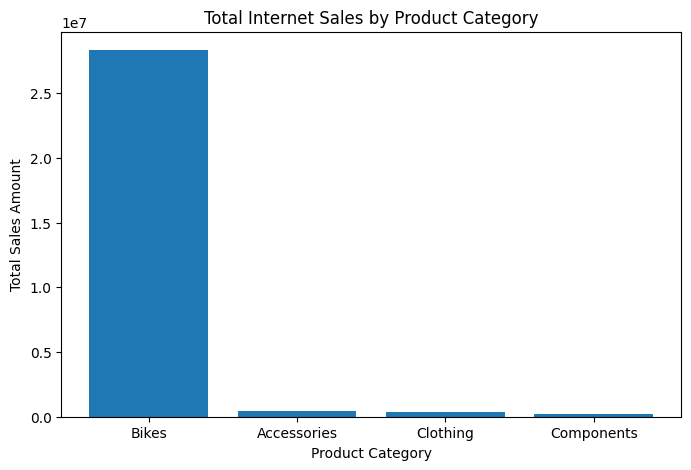

In [13]:
plt.figure(figsize=(8,5))

plt.bar(
    productcategory_sales.index,
    productcategory_sales["TotalSales"]
)

plt.title("Total Internet Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")

In [14]:
sales["HouseOwnerFlag"]

,HouseOwnerFlag
0,1
1,1
2,1
3,1
4,1
...,...
60393,1
60394,1
60395,0
60396,1


In [15]:
homeowner = sales.groupby("HouseOwnerFlag").agg(
    SalesSum=("SalesAmount","sum"),
    SalesAverage=("SalesAmount","mean"),
    SalesCount=("SalesAmount","count")
)

homeowner

,SalesSum,SalesAverage,SalesCount
HouseOwnerFlag,,,
0,8.973327e+06,479.882744,18699
1,2.038535e+07,488.869033,41699


([<matplotlib.axis.XTick at 0x7b7e8208b110>,
 [Text(0, 0, 'Not homeowner'), Text(1, 0, 'homeowner')])

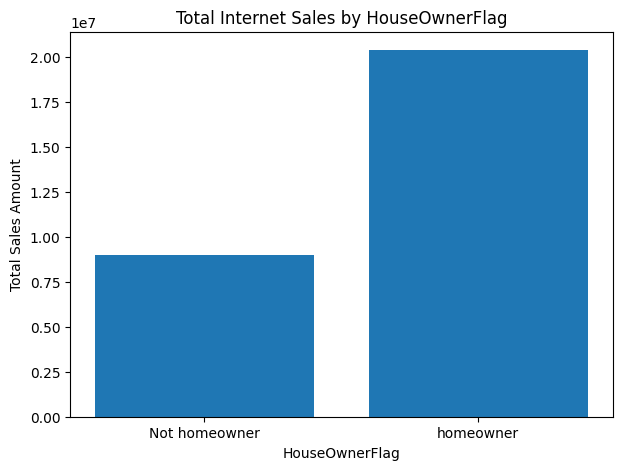

In [16]:
plt.figure(figsize=(7,5))

plt.bar(
    homeowner.index,
    homeowner["SalesSum"]
)

plt.title("Total Internet Sales by HouseOwnerFlag")
plt.xlabel("HouseOwnerFlag")
plt.ylabel("Total Sales Amount")

plt.xticks([0,1],["Not homeowner","homeowner"])